# 03 Parkinson's analysis (completed real-data experiments)
Loads the saved results of `scripts/run_clinical_baseline.py` and `scripts/run_clinical_extended.py` (ds007526 clinical metadata, grouped CV, participant-level bootstrap). EEG-based results are **not yet available**.

In [1]:
import os; os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
import pandas as pd
from IPython.display import Image, display

pd.set_option('display.width', 200)

## E0: PD vs HC from clinical metadata

In [2]:
pd.read_csv('reports/tables/e0_clinical_pd_vs_hc.csv')

,experiment,features,model,n,n_PD,ROC-AUC,PR-AUC,Bal.Acc,Sens,Spec,Brier,ECE
0,E0 PD vs HC,age_only,logreg,144,116,0.681 (0.583-0.777),0.908 (0.856-0.953),0.653,0.698,0.607,0.232,0.281
1,E0 PD vs HC,age_only,rf,144,116,0.632 (0.527-0.726),0.893 (0.841-0.940),0.492,0.698,0.286,0.206,0.207
2,E0 PD vs HC,age_only,svm,144,116,0.608 (0.490-0.720),0.839 (0.760-0.927),0.500,1.000,0.000,0.151,0.075
3,E0 PD vs HC,age_only,xgboost,144,116,0.625 (0.496-0.739),0.837 (0.758-0.928),0.627,0.647,0.607,0.222,0.234
4,E0 PD vs HC,age_only,lightgbm,144,116,0.631 (0.520-0.733),0.873 (0.801-0.940),0.485,0.612,0.357,0.222,0.208
5,E0 PD vs HC,age_sex_moca,logreg,144,116,0.707 (0.598-0.802),0.911 (0.862-0.954),0.650,0.621,0.679,0.217,0.253
6,E0 PD vs HC,age_sex_moca,rf,144,116,0.655 (0.538-0.756),0.892 (0.832-0.942),0.592,0.862,0.321,0.179,0.123
7,E0 PD vs HC,age_sex_moca,svm,144,116,0.620 (0.501-0.722),0.880 (0.816-0.933),0.500,1.000,0.000,0.153,0.035
8,E0 PD vs HC,age_sex_moca,xgboost,144,116,0.653 (0.536-0.756),0.883 (0.816-0.942),0.590,0.716,0.464,0.211,0.201
9,E0 PD vs HC,age_sex_moca,lightgbm,144,116,0.639 (0.524-0.738),0.883 (0.817-0.940),0.536,0.750,0.321,0.211,0.206


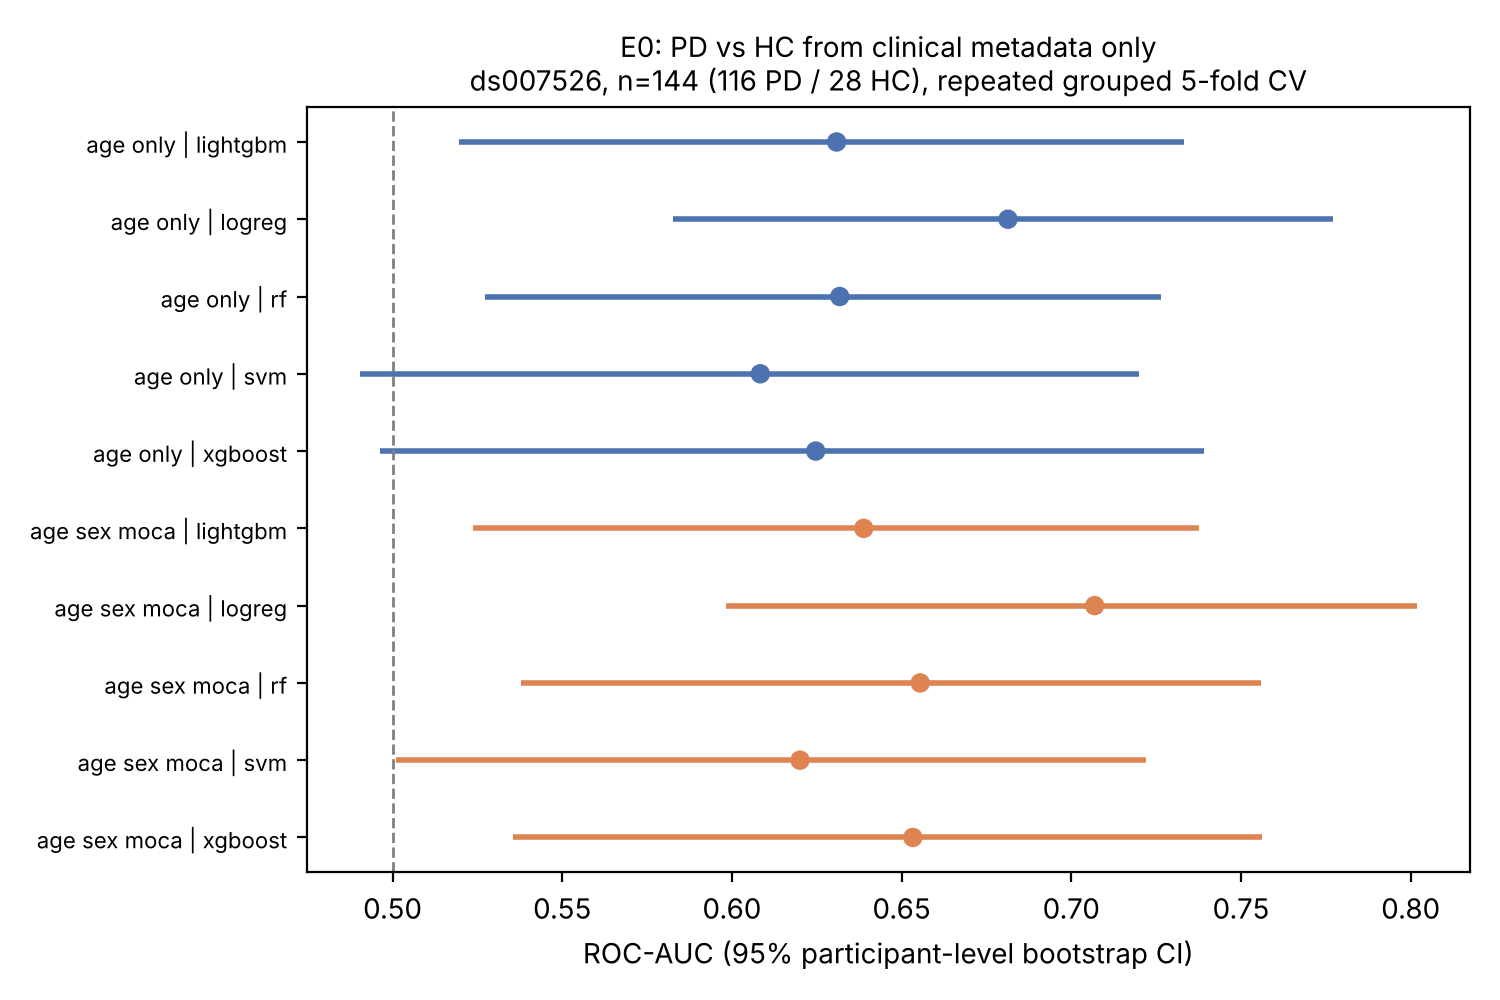

In [3]:
display(Image('reports/figures/e0_clinical_auc_forest.png'))

## E1: UPDRS-III within PD

In [4]:
pd.read_csv('reports/tables/e1_updrs3_severity_in_pd.csv')

,experiment,model,n,MAE,Spearman
0,E1 UPDRS-III in PD,mean_baseline,113,10.16 (8.81-11.57),-0.198
1,E1 UPDRS-III in PD,ridge,113,8.26 (6.93-9.69),0.463
2,E1 UPDRS-III in PD,rf_regressor,113,8.60 (7.29-9.94),0.456


## A1: paired model comparison (participant-level bootstrap, Holm-adjusted)

In [5]:
pd.read_csv('reports/tables/a1_paired_model_comparison.csv').round(3)

,model_a,model_b,auc_diff_mean,ci_lo,ci_hi,p_boot,p_holm,significant_holm_0.05
0,logreg,svm,0.076,-0.013,0.171,0.095,0.950,False
1,rf,svm,0.048,-0.011,0.111,0.111,0.999,False
2,svm,xgboost,-0.038,-0.119,0.034,0.329,1.000,False
3,logreg,xgboost,0.038,-0.051,0.119,0.381,1.000,False
4,svm,lightgbm,-0.040,-0.134,0.055,0.394,1.000,False
5,logreg,rf,0.028,-0.048,0.106,0.464,1.000,False
6,logreg,lightgbm,0.037,-0.067,0.138,0.503,1.000,False
7,rf,xgboost,0.009,-0.049,0.068,0.762,1.000,False
8,rf,lightgbm,0.008,-0.058,0.083,0.846,1.000,False
9,xgboost,lightgbm,-0.001,-0.076,0.072,0.963,1.000,False


## A2: calibration

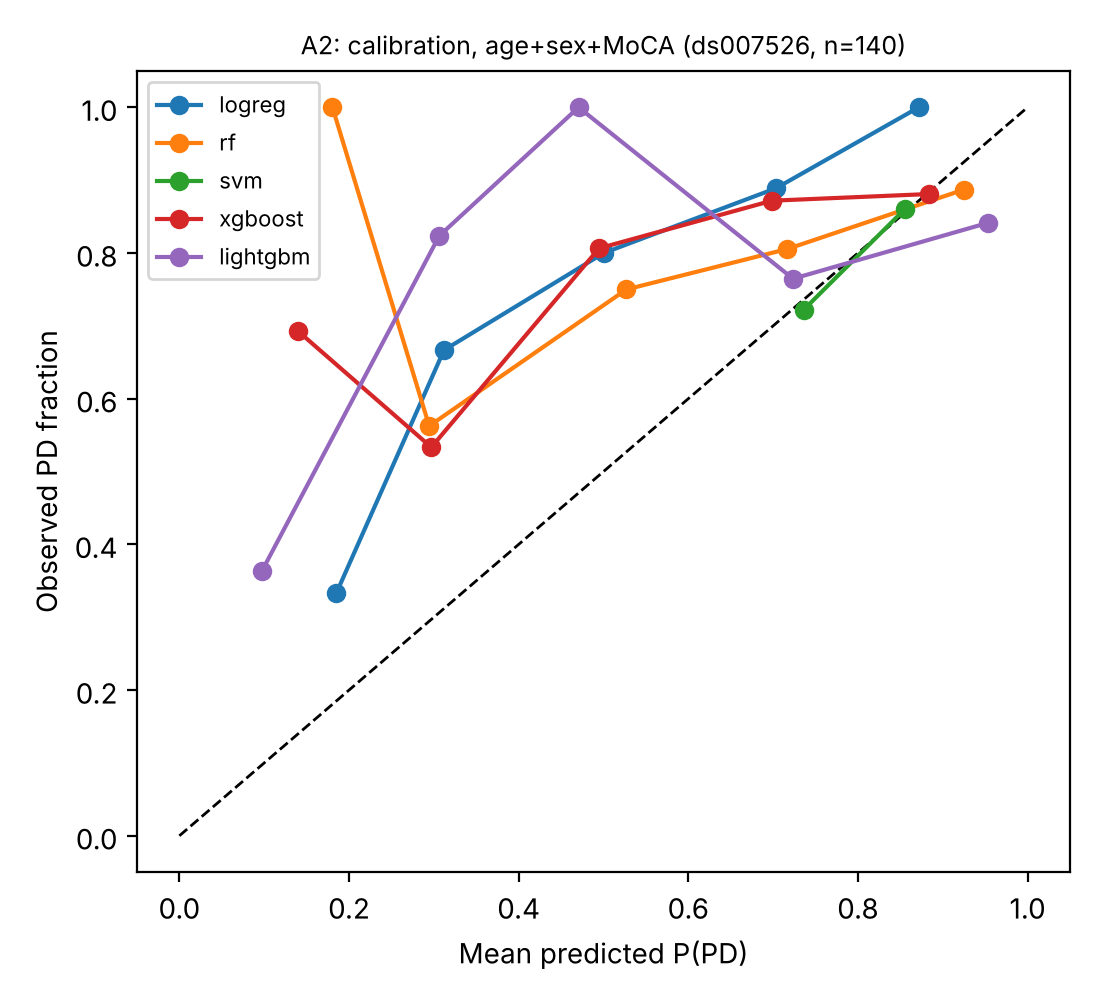

,model,brier,ece
0,logreg,0.217,0.253
1,rf,0.173,0.123
2,svm,0.151,0.013
3,xgboost,0.210,0.204
4,lightgbm,0.202,0.204


In [6]:
display(Image('reports/figures/a2_calibration.png')); pd.read_csv('reports/tables/a2_calibration.csv').round(3)

## A3: age-matched sensitivity analysis
Controls and patients are matched 1:1 on age (caliper 3 y). If clinical AUC collapses to chance, the E0 signal was age confounding.

In [7]:
pd.read_csv('reports/tables/a3_age_matched_sensitivity.csv').round(3)

,features,model,n,n_PD,roc_auc,ci_lo,ci_hi,brier
0,age_only,logreg,54,27,0.346,0.212,0.505,0.256
1,age_only,rf,54,27,0.152,0.051,0.288,0.358
2,sex_moca,logreg,54,27,0.451,0.291,0.616,0.240
3,sex_moca,rf,54,27,0.477,0.321,0.628,0.295
4,age_sex_moca,logreg,54,27,0.433,0.276,0.598,0.246
5,age_sex_moca,rf,54,27,0.372,0.232,0.519,0.307


## A4: sex subgroups and A5: nested CV

In [8]:
display(pd.read_csv('reports/tables/a4_subgroup_sex.csv').round(3)); pd.read_csv('reports/tables/a5_nested_cv.csv').round(3)

,model,subgroup,n,n_HC,roc_auc,ci_lo,ci_hi
0,logreg,female,56,15,0.756,0.612,0.875
1,logreg,male,84,12,0.600,0.439,0.772
2,rf,female,56,15,0.753,0.610,0.870
3,rf,male,84,12,0.481,0.301,0.660
4,svm,female,56,15,0.701,0.545,0.835
5,svm,male,84,12,0.365,0.227,0.517
6,xgboost,female,56,15,0.766,0.624,0.884
7,xgboost,male,84,12,0.429,0.244,0.631
8,lightgbm,female,56,15,0.842,0.709,0.937
9,lightgbm,male,84,12,0.440,0.292,0.590


,model,tuning,n,roc_auc,ci_lo,ci_hi,brier,ece
0,logreg,nested inner 3-fold grouped,140,0.681,0.565,0.783,0.230,0.289
1,rf,nested inner 3-fold grouped,140,0.705,0.596,0.803,0.195,0.215
